# OULAD controlled ablation



## 1. Inputs, environment and provenance

The notebook deliberately **does not regenerate features or folds**. The exact input objects reproduce the original feature definitions, cohort eligibility and within-student grouping used for the manuscript's Table 6. Only two source files are required to reproduce the central analyses:

- `features_cut30.parquet` — **27,526** eligible enrollment records; 56 predictors and target `y`.
- `_folds_c30_g_5x3.pkl` — **15** original train/validation index pairs (five folds, three repetitions).

For local execution, put these files beside the notebook; the code also accepts `/mnt/data`. Recommended versions are recorded at runtime. Parquet reading normally requires `pyarrow` or `fastparquet`; `parquet_read_min.py` is supplied in the companion package as an environment-specific fallback. The pickle is read using a **restricted** NumPy-only unpickler; still, use only author-supplied trusted data.

**Other files** (day 60, full-cohort, UCI, raw VLE aggregations) belong to different prediction horizons or analyses and are intentionally excluded. All derived tables and figures are written to `oulad_ablation_rep_results/`.

In [1]:
import hashlib
import json
import os
import pickle
import warnings
from pathlib import Path

# Set before importing NumPy / BLAS-backed libraries.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import imblearn
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import OneHotEncoder
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
CUTOFF_DAY = 30
DECISION_THRESHOLD = 0.50
N_BOOTSTRAP = 600

# Prefer the notebook folder; support this notebook's hosted execution path.
CANDIDATE_ROOTS = [Path.cwd(), Path("/mnt/data"), Path.cwd() / "data"]
DATA_ROOT = next((p for p in CANDIDATE_ROOTS
                  if (p / "features_cut30.parquet").is_file()
                  and (p / "_folds_c30_g_5x3.pkl").is_file()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Place features_cut30.parquet and _folds_c30_g_5x3.pkl beside this notebook.")
FEATURE_FILE = DATA_ROOT / "features_cut30.parquet"
FOLD_FILE = DATA_ROOT / "_folds_c30_g_5x3.pkl"
RESULTS_DIR = DATA_ROOT / "oulad_ablation_rep_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    """Checksum for traceable replication inputs."""
    h = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("Python environment / key library versions:")
print(f"  numpy={np.__version__}; pandas={pd.__version__}; scipy={scipy.__version__}")
print(f"  scikit-learn={sklearn.__version__}; imbalanced-learn={imblearn.__version__}")
print("Data root:", DATA_ROOT)
print("Input checksums:")
print("  features_cut30:", sha256_file(FEATURE_FILE))
print("  original folds:", sha256_file(FOLD_FILE))

Python environment / key library versions:
  numpy=2.3.5; pandas=2.2.3; scipy=1.17.0
  scikit-learn=1.8.0; imbalanced-learn=0.14.1
Data root: /mnt/data
Input checksums:
  features_cut30: c106fd59cd105205ff83b7d62b4089f2594cdb093a65e06b81f0487d78fc8421
  original folds: ba4198a8ecf64f04d24498bb24506c1c0ed2881f66926e90935674fa3d34662f


## 2. Cohort integrity, original folds and predictor taxonomy

**Unit of analysis:** student–course presentation record. The same student can have multiple records. **Target:** `y=1` denotes a future withdrawal among students retained in the original day-30 analytic cohort. A random record-level split would risk placing the same student in both training and validation, so all 15 original splits must be checked for group separation.

**Five predictor families (56 variables in total):**

| Code | Meaning | Number of predictors | Interpretation |
|:--|:--|--:|:--|
| `ACAD` | Academic history and early assessments | 13 | Academic information |
| `DEMO` | Demographics | 4 | Demographic attributes |
| `SOCIO` | Socioeconomic context | 2 | Socioeconomic attributes |
| `INST` | Institutional and presentation attributes | 8 | Course/presentation metadata and registration |
| `BEH` | **Behavioral-engagement proxies** | 29 | Observable VLE clicks, timing, activity distributions and submission behavior |

The original code named the last group `PSI`. Here we **rename its label to `BEH` without changing any features**. These data are *not* validated measures of psychological constructs such as belonging, motivation or self-efficacy. The taxonomy change is descriptive, not a new experiment.

**Temporal-availability limitation:** the provided engineered Parquet does not, by itself, prove that every derived feature was computable using data observed strictly before day 30. We therefore record late-registration anomalies and explicitly flag the need to audit early assessment dates and cohort-size metadata against feature-generation code. We preserve the original cohort for comparability rather than silently dropping records.

In [2]:
# Load the author-supplied features rather than recomputing them.
try:
    frame = pd.read_parquet(FEATURE_FILE)
    read_backend = "pandas/Parquet engine"
except ImportError:
    # Optional helper for the execution environment; prefer pyarrow for general use.
    import sys
    sys.path.insert(0, str(DATA_ROOT))
    from parquet_read_min import readparquet
    frame = readparquet(str(FEATURE_FILE))
    read_backend = "bundled narrow Parquet fallback"

if "id_student" in frame.columns:
    student_ids = frame["id_student"].to_numpy()
else:
    student_ids = frame.index.get_level_values("id_student").to_numpy()
labels = frame["y"].to_numpy(dtype=int)
features = frame.drop(columns=["y", "y_recat", "id_student",
                               "__index_level_1__", "__index_level_2__"],
                      errors="ignore").reset_index(drop=True)
assert features.shape == (27_526, 56), f"Unexpected feature shape: {features.shape}"
assert set(np.unique(labels)) == {0, 1}
assert len(student_ids) == len(labels)

# Keep the original 56 columns and their grouping; no feature recomputation.
FEATURE_FAMILIES = {
    "ACAD": ["num_intentos_previos", "creditos_estudiados", "educacion_previa_ord",
             "n_evals_programadas", "n_evals_entregadas", "tasa_entrega",
             "nota_media", "nota_min", "nota_ponderada", "alguna_reprobada",
             "alguna_nota_banked", "sin_evaluacion_previa", "sin_entrega_previa"],
    "DEMO": ["genero", "discapacidad", "region", "franja_edad_ord"],
    "SOCIO": ["imd_band_ord", "imd_desconocido"],
    "INST": ["code_module", "code_presentation", "anio_presentacion",
             "semestre_presentacion", "duracion_presentacion",
             "dias_anticipacion_registro", "registro_desconocido", "tamano_cohorte"],
    "BEH": ["clics_total_pre_corte", "clics_pre_inicio", "dias_activos",
            "clics_medios_por_dia_activo", "clics_max_dia",
            "entropia_compromiso", "cv_clics_diarios", "racha_inactividad_max",
            "dias_desde_ultimo_clic", "dia_primer_clic", "semanas_activas",
            "flag_inactividad_temprana", "pendiente_tendencia_clics",
            "ratio_sem_final_inicial", "sin_actividad_vle",
            "n_sitios_distintos", "n_tipos_actividad", "entropia_tipos_actividad",
            "share_forumng", "share_quiz", "share_oucontent", "share_resource",
            "share_subpage", "share_homepage", "intensidad_quiz_por_evaluacion",
            "adelanto_medio_entrega", "n_entregas_tardias",
            "tasa_entrega_tardia", "n_evals_no_entregadas"]
}
CATEGORICAL_COLUMNS = ["genero", "discapacidad", "region", "code_module",
                       "code_presentation", "semestre_presentacion"]
assert {k: len(v) for k, v in FEATURE_FAMILIES.items()} == {
    "ACAD": 13, "DEMO": 4, "SOCIO": 2, "INST": 8, "BEH": 29}
assert set(c for names in FEATURE_FAMILIES.values() for c in names) == set(features.columns)

def select_columns(family_names):
    """Preserve the original within-family feature order."""
    return [column for family in family_names for column in FEATURE_FAMILIES[family]]

class NumPyOnlyUnpickler(pickle.Unpickler):
    """Restrict pickle deserialization to the NumPy array types used by these folds."""
    def find_class(self, module, name):
        permitted = {"numpy._core.multiarray": {"_reconstruct"},
                     "numpy.core.multiarray": {"_reconstruct"},
                     "numpy": {"ndarray", "dtype"}}
        if name in permitted.get(module, set()):
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"Forbidden pickle global: {module}.{name}")

with FOLD_FILE.open("rb") as handle:
    original_folds = NumPyOnlyUnpickler(handle).load()
assert len(original_folds) == 15
assert sorted((int(r), int(f)) for r, f, _, _ in original_folds) == [
    (r, f) for r in range(3) for f in range(5)]
for repeat, fold, train_ids, test_ids in original_folds:
    assert 0 <= train_ids.min() and train_ids.max() < len(features)
    assert 0 <= test_ids.min() and test_ids.max() < len(features)
    assert len(np.intersect1d(train_ids, test_ids)) == 0
    assert len(np.intersect1d(student_ids[train_ids], student_ids[test_ids])) == 0

late_registration_count = int((features["dias_anticipacion_registro"] < -CUTOFF_DAY).sum())
print(f"Read backend: {read_backend}")
print(f"Records: {len(features):,}; predictors: {features.shape[1]}; unique students: {len(np.unique(student_ids)):,}")
print(f"Withdrawals: {labels.sum():,}; prevalence: {labels.mean():.4%}")
print("Presentation counts:", features.code_presentation.value_counts().sort_index().to_dict())
print("Feature families:", {k: len(v) for k, v in FEATURE_FAMILIES.items()})
print("Original grouped CV partitions validated: 5 folds × 3 repetitions =", len(original_folds))
print(f"Potential post-cutoff registration records (retained for replication): {late_registration_count}")
assert late_registration_count == 16, "Eligibility-audit count differs from the expected source cohort."

Read backend: bundled narrow Parquet fallback
Records: 27,526; predictors: 56; unique students: 24,829
Withdrawals: 5,097; prevalence: 18.5170%
Presentation counts: {'2013B': 4124, '2013J': 7682, '2014B': 6510, '2014J': 9210}
Feature families: {'ACAD': 13, 'DEMO': 4, 'SOCIO': 2, 'INST': 8, 'BEH': 29}
Original grouped CV partitions validated: 5 folds × 3 repetitions = 15
Potential post-cutoff registration records (retained for replication): 16


## 3. Fixed estimator, preprocessing and original cross-validation ablations

**Controlled comparison.** The Random Forest and all preprocessing parameters are fixed across feature configurations. The model has 200 trees, `max_depth=12`, `min_samples_leaf=20`, `max_features='sqrt'`, `criterion='gini'`, bootstrap sampling, and seed 42. Standard training uses `class_weight=None`; the **cost-sensitive** arm alone uses `class_weight='balanced'` as the manipulated treatment. We do not tune the threshold (fixed at **0.50**) or hyperparameters using held-out observations.

**Leakage safeguards.** The imputer, encoder, variance filter, and any resampling operation are nested in a pipeline **fit only on each training fold**. Validation folds retain natural class prevalence. Numeric values are imputed with the median and a missingness indicator; nominal values receive constant imputation then one-hot encoding (`min_frequency=0.01`), followed by nonzero-variance filtering.

**Compatibility note on SMOTE-NC:** the original sampler flags post-encoding 0/1 variables as categorical. This mirrors the source experiment but cannot guarantee that synthetic one-hot combinations represent valid original categories. It should not be silently replaced in a manuscript replication; a pre-encoding categorical sampler would be a separate sensitivity analysis.

**Transformation traceability:** The supplied original Random Forest notebook omits `log1p` transformations and feature scaling in the modeled pipeline. This reproduction preserves that choice. If the manuscript currently describes an additional log transformation, reconcile that wording against the feature-engineering provenance before submitting a revised methods section; do not assert an unexecuted transform.

In [3]:
def make_preprocessor(columns):
    """Build a fresh training-only transformer for a given predictor subset."""
    nominal = [column for column in columns if column in CATEGORICAL_COLUMNS]
    numeric = [column for column in columns if column not in nominal]
    transformers = []
    if numeric:
        transformers.append(("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric))
    if nominal:
        category_pipeline = SklearnPipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Desconocido")),
            ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                     min_frequency=0.01, sparse_output=False))
        ])
        transformers.append(("categorical", category_pipeline, nominal))
    return ColumnTransformer(transformers, remainder="drop")


def make_random_forest(cost_sensitive=False):
    """Frozen classifier; class weights change only in the corresponding ablation."""
    return RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, max_depth=12,
        max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1,
        class_weight="balanced" if cost_sensitive else None,
    )


class OriginalSmoteNC:
    """Replicate the original post-OHE 0/1-column detection for SMOTE-NC."""
    def __init__(self, random_state=RANDOM_STATE, k_neighbors=5):
        self.random_state = random_state
        self.k_neighbors = k_neighbors

    def get_params(self, deep=True):
        return {"random_state": self.random_state, "k_neighbors": self.k_neighbors}

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

    def fit_resample(self, X, y):
        values = np.asarray(X, dtype=float)
        categorical_indices = [index for index in range(values.shape[1])
                               if np.isin(np.unique(values[:, index]), [0.0, 1.0]).all()]
        if not categorical_indices or len(categorical_indices) == values.shape[1]:
            return SMOTE(random_state=self.random_state,
                         k_neighbors=self.k_neighbors).fit_resample(values, y)
        return SMOTENC(categorical_features=categorical_indices,
                       random_state=self.random_state,
                       k_neighbors=self.k_neighbors).fit_resample(values, y)


def make_pipeline(columns, balancing="NONE"):
    """Fit preprocessing and resampling inside the training partition only."""
    steps = [("prepare", make_preprocessor(columns)),
             ("variance", VarianceThreshold(0.0))]
    if balancing == "SMOTENC":
        steps.append(("resample", OriginalSmoteNC()))
    elif balancing == "UNDERSAMPLING":
        steps.append(("resample", RandomUnderSampler(
            sampling_strategy=1.0, random_state=RANDOM_STATE)))
    steps.append(("classifier", make_random_forest(cost_sensitive=(balancing == "COST_SENSITIVE"))))
    return ImbalancedPipeline(steps)


def evaluate_binary_outcome(y_true, probabilities):
    """Report thresholded dropout metrics plus threshold-independent ranking metrics."""
    predictions = (probabilities >= DECISION_THRESHOLD).astype(int)
    return {"precision": precision_score(y_true, predictions, zero_division=0),
            "recall": recall_score(y_true, predictions, zero_division=0),
            "f1": f1_score(y_true, predictions, zero_division=0),
            "ap": average_precision_score(y_true, probabilities),
            "auroc": roc_auc_score(y_true, probabilities)}

# In this notebook, 'AP' always means average_precision_score — sometimes called PR-AUC.
print("Fixed RF and fold-safe pipelines initialized; F1 threshold =", DECISION_THRESHOLD)

Fixed RF and fold-safe pipelines initialized; F1 threshold = 0.5


### 3.1. Feature-family arms: independent additions and cumulative sequence

The **academic-only baseline** (`ACAD`) is compared with each non-academic family added *one at a time*. We also reproduce the original academic + behavioral and all-feature arms and report two intermediate cumulative configurations. This sequence tests whether adding information improves prediction **conditional on the existing feature set**; it does not identify causal contributions of the underlying student characteristics.

The same 15 **original** train/test partitions are used for all arms. Each fit starts with an independent pipeline. The primary outputs are **fold-level metrics**, with absolute Δ relative to `ACAD`.

In [4]:
FEATURE_ARMS = {
    "ACAD": ["ACAD"],
    "ACAD+BEH": ["ACAD", "BEH"],
    "ACAD+DEMO": ["ACAD", "DEMO"],
    "ACAD+SOCIO": ["ACAD", "SOCIO"],
    "ACAD+INST": ["ACAD", "INST"],
    "ACAD+BEH+DEMO": ["ACAD", "BEH", "DEMO"],
    "ACAD+BEH+DEMO+SOCIO": ["ACAD", "BEH", "DEMO", "SOCIO"],
    "ALL": ["ACAD", "DEMO", "SOCIO", "INST", "BEH"],
}

feature_fold_rows = []
for arm_name, families in FEATURE_ARMS.items():
    selected = select_columns(families)
    for repeat, fold, train, test in original_folds:
        model = make_pipeline(selected)
        model.fit(features.iloc[train][selected], labels[train])
        probabilities = model.predict_proba(features.iloc[test][selected])[:, 1]
        feature_fold_rows.append({
            "block": "features", "arm": arm_name,
            "repeat": int(repeat), "fold": int(fold),
            "test_train_ratio": len(test) / len(train),
            "n_features": len(selected),
            **evaluate_binary_outcome(labels[test], probabilities)
        })
    arm_data = pd.DataFrame(row for row in feature_fold_rows if row["arm"] == arm_name)
    print(f"{arm_name:24}  F1={arm_data.f1.mean():.4f}   AP={arm_data.ap.mean():.4f}", flush=True)

feature_cv = pd.DataFrame(feature_fold_rows)
feature_cv.to_csv(RESULTS_DIR / "cv_feature_folds.csv", index=False)

def summarize_by_arm(dataframe, reference):
    """Mean metrics and absolute differences to one explicitly specified baseline."""
    means = dataframe.groupby("arm", sort=False)[["precision", "recall", "f1", "ap", "auroc"]].mean()
    means["delta_f1"] = means["f1"] - means.loc[reference, "f1"]
    means["delta_ap"] = means["ap"] - means.loc[reference, "ap"]
    return means.reset_index()

feature_cv_summary = summarize_by_arm(feature_cv, "ACAD")
feature_cv_summary.to_csv(RESULTS_DIR / "cv_feature_summary.csv", index=False)
print("\nOriginal-fold grouped CV: means and absolute changes vs. ACAD")
print(feature_cv_summary.round(4).to_string(index=False))

ACAD                      F1=0.0964   AP=0.3521


ACAD+BEH                  F1=0.1002   AP=0.3694


ACAD+DEMO                 F1=0.0863   AP=0.3584


ACAD+SOCIO                F1=0.1002   AP=0.3527


ACAD+INST                 F1=0.1687   AP=0.3786


ACAD+BEH+DEMO             F1=0.0875   AP=0.3721


ACAD+BEH+DEMO+SOCIO       F1=0.0848   AP=0.3720


ALL                       F1=0.1226   AP=0.3870



Original-fold grouped CV: means and absolute changes vs. ACAD
                arm  precision  recall     f1     ap  auroc  delta_f1  delta_ap
               ACAD     0.5787  0.0527 0.0964 0.3521 0.6820    0.0000    0.0000
           ACAD+BEH     0.5723  0.0550 0.1002 0.3694 0.7041    0.0037    0.0173
          ACAD+DEMO     0.5902  0.0467 0.0863 0.3584 0.6878   -0.0101    0.0063
         ACAD+SOCIO     0.5687  0.0551 0.1002 0.3527 0.6820    0.0038    0.0006
          ACAD+INST     0.5896  0.0985 0.1687 0.3786 0.6981    0.0723    0.0264
      ACAD+BEH+DEMO     0.5917  0.0473 0.0875 0.3721 0.7072   -0.0089    0.0199
ACAD+BEH+DEMO+SOCIO     0.6096  0.0456 0.0848 0.3720 0.7075   -0.0116    0.0198
                ALL     0.6029  0.0683 0.1226 0.3870 0.7160    0.0262    0.0348


**Interpretation — feature-family CV.** The original arms are closely reproduced: `ACAD` gives **F1 ≈ 0.0964, AP ≈ 0.3521**; adding behavioral engagement gives **F1 ≈ 0.1002, AP ≈ 0.3694**; and `ALL` gives **F1 ≈ 0.1226, AP ≈ 0.3870**. Thus `ALL − ACAD` is approximately **+0.0262 F1 points** and **+0.0348 AP points**. Do not describe these as relative percentage increases.

The enlarged arms are informative rather than redundant. Notably, `ACAD+INST` attains **F1 ≈ 0.1687**, greater than the all-feature model's F1, while `ALL` retains the higher AP. The selected best arm therefore depends on the metric, and the inclusion of a family need not monotonically improve the thresholded outcome.

### 3.2. Class-imbalance ablation on the full feature set

Hold the **`ALL`** predictor set fixed and compare (i) natural prevalence (`NONE`), (ii) original post-encoding SMOTE-NC (`SMOTENC`), (iii) random undersampling and (iv) class weighting. The no-balancing baseline is identical to `ALL` in §3.1 and is **reused without refitting**. All resampling remains inside training folds.

In [5]:
BALANCING_ARMS = ["NONE", "SMOTENC", "UNDERSAMPLING", "COST_SENSITIVE"]
all_columns = select_columns(FEATURE_ARMS["ALL"])

balance_fold_rows = []
for balancing in BALANCING_ARMS:
    if balancing == "NONE":
        # Reuse identical predictions/metrics from the all-feature arm.
        for row in feature_fold_rows:
            if row["arm"] == "ALL":
                balance_fold_rows.append({**row, "block": "balancing", "arm": "NONE"})
    else:
        for repeat, fold, train, test in original_folds:
            model = make_pipeline(all_columns, balancing)
            model.fit(features.iloc[train][all_columns], labels[train])
            probabilities = model.predict_proba(features.iloc[test][all_columns])[:, 1]
            balance_fold_rows.append({
                "block": "balancing", "arm": balancing,
                "repeat": int(repeat), "fold": int(fold),
                "test_train_ratio": len(test) / len(train),
                "n_features": len(all_columns),
                **evaluate_binary_outcome(labels[test], probabilities)
            })
    arm_data = pd.DataFrame(row for row in balance_fold_rows if row["arm"] == balancing)
    print(f"{balancing:18} F1={arm_data.f1.mean():.4f}   AP={arm_data.ap.mean():.4f}", flush=True)

balance_cv = pd.DataFrame(balance_fold_rows)
balance_cv.to_csv(RESULTS_DIR / "cv_balancing_folds.csv", index=False)
balance_cv_summary = summarize_by_arm(balance_cv, "NONE")
balance_cv_summary.to_csv(RESULTS_DIR / "cv_balancing_summary.csv", index=False)
print("\nOriginal-fold grouped CV: balancing means and absolute changes vs. no balancing")
print(balance_cv_summary.round(4).to_string(index=False))

NONE               F1=0.1226   AP=0.3870


SMOTENC            F1=0.3543   AP=0.3548


UNDERSAMPLING      F1=0.4139   AP=0.3766


COST_SENSITIVE     F1=0.4219   AP=0.3846



Original-fold grouped CV: balancing means and absolute changes vs. no balancing
           arm  precision  recall     f1     ap  auroc  delta_f1  delta_ap
          NONE     0.6029  0.0683 0.1226 0.3870 0.7160    0.0000    0.0000
       SMOTENC     0.4095  0.3124 0.3543 0.3548 0.6992    0.2317   -0.0322
 UNDERSAMPLING     0.3189  0.5902 0.4139 0.3766 0.7112    0.2913   -0.0103
COST_SENSITIVE     0.3672  0.4962 0.4219 0.3846 0.7140    0.2992   -0.0024


**Interpretation — imbalance CV.** Relative to no balancing (**F1 ≈ 0.1226; AP ≈ 0.3870**), SMOTE-NC, undersampling, and cost-sensitive weighting yield much larger **F1@0.50**, principally through substantially higher recall, but do **not** increase AP in this repeated-CV setting. This is a change in the operating characteristics of a fixed-threshold classifier, not evidence that balancing necessarily improves risk ranking. The direction of the AP contrast should be reported alongside F1 to avoid one-metric conclusions.

## 4. Inference appropriate for overlapping cross-validation folds

The original analysis used Wilcoxon tests on **15 overlapping folds**. These scores are dependent because training sets overlap, so an uncorrected test can understate uncertainty. Here we use the **Nadeau–Bengio corrected repeated-resampling *t*-test** on matched fold-wise differences. For \(m=15\) paired differences \(d_i\):

\[
\bar{d}=m^{-1}\sum_{i=1}^m d_i,\qquad
SE_{\mathrm{corr}}(\bar{d})=s_d\sqrt{\frac{1}{m}+\overline{\frac{n_{test}}{n_{train}}}},\qquad
t=\frac{\bar{d}}{SE_{\mathrm{corr}}(\bar{d})}.
\]

We use \(m-1=14\) degrees of freedom and report **two-sided** per-comparison 95% corrected-*t* intervals. **Holm-adjusted p-values are computed separately for each endpoint and experimental block.** The unadjusted 95% intervals are **not simultaneous confidence intervals**: a corrected CI may exclude zero even when the Holm-adjusted p-value exceeds 0.05.

Two feature families of hypotheses are distinguished:

1. **Original contrasts:** only `ACAD+BEH` and `ALL` vs `ACAD` (two per endpoint), reflecting the manuscript's pre-existing analysis.
2. **Expanded exploratory contrasts:** all seven non-baseline feature arms vs `ACAD` (seven per endpoint). A favorable multiple-testing family must not be selected post hoc.

This corrected *t*-test is an **approximation**, not a guarantee of independent folds or generalizability beyond OULAD.

In [6]:
def holm_adjust(p_values):
    """Holm step-down family-wise error correction, retaining input order."""
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p_values), np.nan)
    ordered = np.argsort(p_values)
    running_max = 0.0
    for rank, index in enumerate(ordered):
        if not np.isfinite(p_values[index]):
            continue
        running_max = max(running_max, min(1.0, (len(p_values) - rank) * p_values[index]))
        adjusted[index] = running_max
    return adjusted


def corrected_repeated_cv_test(fold_scores, reference, endpoints=("f1", "ap")):
    """Paired Nadeau–Bengio correction using the original grouped folds."""
    paired = fold_scores.pivot(index=["repeat", "fold"], columns="arm", values=list(endpoints))
    test_train_ratio = fold_scores.drop_duplicates(["repeat", "fold"])["test_train_ratio"].mean()
    records = []
    for arm in fold_scores["arm"].unique():
        if arm == reference:
            continue
        for endpoint in endpoints:
            differences = (paired[(endpoint, arm)] - paired[(endpoint, reference)]).to_numpy()
            sample_size = len(differences)
            se = differences.std(ddof=1) * np.sqrt(1 / sample_size + test_train_ratio)
            statistic = differences.mean() / se if se > 0 else np.nan
            p_value = 2 * stats.t.sf(abs(statistic), sample_size - 1) if np.isfinite(statistic) else np.nan
            critical = stats.t.ppf(0.975, sample_size - 1)
            records.append({
                "arm": arm, "reference": reference, "metric": endpoint,
                "delta_absolute": float(differences.mean()),
                "ci95_lower": float(differences.mean() - critical * se),
                "ci95_upper": float(differences.mean() + critical * se),
                "p_unadjusted": p_value, "n_paired_folds": sample_size,
                "mean_test_train_ratio": float(test_train_ratio)
            })
    out = pd.DataFrame(records)
    for endpoint in endpoints:
        is_endpoint = out.metric.eq(endpoint)
        out.loc[is_endpoint, "p_holm"] = holm_adjust(
            out.loc[is_endpoint, "p_unadjusted"].to_numpy())
    return out

feature_tests_expanded = corrected_repeated_cv_test(feature_cv, "ACAD")
balancing_tests = corrected_repeated_cv_test(balance_cv, "NONE")

# Original two contrasts: correction is deliberately restricted to the pre-existing arms.
original_arm_scores = feature_cv[feature_cv.arm.isin(["ACAD", "ACAD+BEH", "ALL"])]
feature_tests_original = corrected_repeated_cv_test(original_arm_scores, "ACAD")

feature_tests_expanded.to_csv(RESULTS_DIR / "cv_corrected_t_features_expanded.csv", index=False)
feature_tests_original.to_csv(RESULTS_DIR / "cv_corrected_t_features_original.csv", index=False)
balancing_tests.to_csv(RESULTS_DIR / "cv_corrected_t_balancing.csv", index=False)

print("EXPANDED FEATURE FAMILY — corrected t and Holm (absolute changes):")
print(feature_tests_expanded[["arm", "metric", "delta_absolute", "ci95_lower", "ci95_upper", "p_holm"]]
      .round(5).to_string(index=False))
print("\nORIGINAL TWO CONTRASTS — corrected t and Holm:")
print(feature_tests_original[["arm", "metric", "delta_absolute", "p_holm"]]
      .round(5).to_string(index=False))
print("\nBALANCING — corrected t and Holm:")
print(balancing_tests[["arm", "metric", "delta_absolute", "p_holm"]]
      .round(5).to_string(index=False))

EXPANDED FEATURE FAMILY — corrected t and Holm (absolute changes):
                arm metric  delta_absolute  ci95_lower  ci95_upper  p_holm
           ACAD+BEH     f1         0.00374    -0.01363     0.02111 0.81176
           ACAD+BEH     ap         0.01727     0.00659     0.02795 0.01129
          ACAD+DEMO     f1        -0.01009    -0.02168     0.00149 0.41401
          ACAD+DEMO     ap         0.00631     0.00078     0.01183 0.05623
         ACAD+SOCIO     f1         0.00382    -0.00332     0.01097 0.81176
         ACAD+SOCIO     ap         0.00061    -0.00252     0.00373 0.68315
          ACAD+INST     f1         0.07233     0.05551     0.08916 0.00000
          ACAD+INST     ap         0.02642     0.01909     0.03375 0.00001
      ACAD+BEH+DEMO     f1        -0.00886    -0.02568     0.00795 0.81176
      ACAD+BEH+DEMO     ap         0.01993     0.00959     0.03027 0.00406
ACAD+BEH+DEMO+SOCIO     f1        -0.01164    -0.02731     0.00403 0.53405
ACAD+BEH+DEMO+SOCIO     ap       

**Statistical reading.** Adding BEH to ACAD improves **AP by approximately +0.0173** (expanded Holm-adjusted **p ≈ 0.0113**), but its **F1 gain of +0.0037 is not significant**. The all-feature configuration increases AP by **≈ +0.0348**, remaining significant under the expanded adjustment. In contrast, its F1 increase of **≈ +0.0262** yields **p ≈ 0.0785** when all seven exploratory feature comparisons are corrected; under the original two-comparison family, its adjusted p-value is **≈ 0.0262**. These are different inferential scopes, **not contradictory model results**.

In the balancing block, larger F1 contrasts coexist with AP losses or negligible AP changes. Do not label *all* improvements significant based on F1 alone. All inferential statements here are conditional on the chosen model, fold scheme, and OULAD data.

## 5. Temporal hold-out — train on earlier presentations, test on 2014J

**Chronology.** Use the earlier presentations `2013B`, `2013J`, and `2014B` for training; reserve **all `2014J` records** for a single untouched evaluation. To avoid student identity leakage, remove from training **every record of any student observed in `2014J`**. This is stricter than simply filtering by presentation.

The resulting test is a **temporal generalization check within OULAD**. It is not independent validation on a different university. Preserve all hyperparameters, feature families, preprocessing, decision threshold and balancing definitions. The temporal test is not used to tune a threshold or choose a model configuration.

In [7]:
# This split is *not* one of the fifteen CV folds.
test_positions = np.flatnonzero(features.code_presentation.eq("2014J").to_numpy())
source_is_earlier = features.code_presentation.isin(["2013B", "2013J", "2014B"]).to_numpy()
held_out_students = np.unique(student_ids[test_positions])
train_positions = np.flatnonzero(source_is_earlier & ~np.isin(student_ids, held_out_students))

assert len(np.intersect1d(student_ids[train_positions], student_ids[test_positions])) == 0
assert set(features.iloc[train_positions].code_presentation).issubset({"2013B", "2013J", "2014B"})
assert features.iloc[test_positions].code_presentation.eq("2014J").all()
purged_rows = int(source_is_earlier.sum() - len(train_positions))
print(f"Training: {len(train_positions):,} records; withdrawal prevalence {labels[train_positions].mean():.4%}")
print(f"2014J hold-out: {len(test_positions):,} records; withdrawal prevalence {labels[test_positions].mean():.4%}")
print(f"Earlier-presentation rows excluded for student ID overlap: {purged_rows:,}")
print("Student identifiers overlap between train and test: 0")

# Fit one model per family configuration, only on earlier, non-overlapping students.
temporal_feature_probs = {}
temporal_feature_rows = []
for arm, families in FEATURE_ARMS.items():
    cols = select_columns(families)
    model = make_pipeline(cols)
    model.fit(features.iloc[train_positions][cols], labels[train_positions])
    prob = model.predict_proba(features.iloc[test_positions][cols])[:, 1]
    temporal_feature_probs[arm] = prob
    temporal_feature_rows.append({"arm": arm, "n_features": len(cols),
                                  **evaluate_binary_outcome(labels[test_positions], prob)})
    print(f"{arm:24} F1={temporal_feature_rows[-1]['f1']:.4f}; AP={temporal_feature_rows[-1]['ap']:.4f}", flush=True)

temporal_features = pd.DataFrame(temporal_feature_rows)
for endpoint in ["f1", "ap"]:
    temporal_features[f"delta_{endpoint}"] = temporal_features[endpoint] - (
        temporal_features.loc[temporal_features.arm.eq("ACAD"), endpoint].iloc[0])
temporal_features.to_csv(RESULTS_DIR / "temporal_features_2014J.csv", index=False)
print("\n2014J hold-out — features, absolute deltas vs ACAD")
print(temporal_features.round(4).to_string(index=False))

Training: 16,965 records; withdrawal prevalence 16.5281%
2014J hold-out: 9,210 records; withdrawal prevalence 19.2834%
Earlier-presentation rows excluded for student ID overlap: 1,351
Student identifiers overlap between train and test: 0


ACAD                     F1=0.1263; AP=0.2626


ACAD+BEH                 F1=0.0508; AP=0.2892


ACAD+DEMO                F1=0.1151; AP=0.2634


ACAD+SOCIO               F1=0.1218; AP=0.2637


ACAD+INST                F1=0.0425; AP=0.2931


ACAD+BEH+DEMO            F1=0.0380; AP=0.2927


ACAD+BEH+DEMO+SOCIO      F1=0.0369; AP=0.2952


ALL                      F1=0.0222; AP=0.3217



2014J hold-out — features, absolute deltas vs ACAD
                arm  n_features  precision  recall     f1     ap  auroc  delta_f1  delta_ap
               ACAD          13     0.2053  0.0912 0.1263 0.2626 0.6223    0.0000    0.0000
           ACAD+BEH          42     0.4174  0.0270 0.0508 0.2892 0.6521   -0.0755    0.0266
          ACAD+DEMO          17     0.1921  0.0822 0.1151 0.2634 0.6287   -0.0112    0.0008
         ACAD+SOCIO          15     0.2016  0.0873 0.1218 0.2637 0.6271   -0.0045    0.0011
          ACAD+INST          21     0.6724  0.0220 0.0425 0.2931 0.6317   -0.0838    0.0306
      ACAD+BEH+DEMO          46     0.5303  0.0197 0.0380 0.2927 0.6527   -0.0883    0.0301
ACAD+BEH+DEMO+SOCIO          48     0.5000  0.0191 0.0369 0.2952 0.6590   -0.0894    0.0327
                ALL          56     0.7407  0.0113 0.0222 0.3217 0.6603   -0.1041    0.0591


**Interpretation — temporal feature generalization.** In `2014J`, the all-feature model achieves **AP ≈ 0.3217** versus **0.2626** for ACAD (**Δ AP ≈ +0.0591**), yet its **F1@0.50 ≈ 0.0222** versus **0.1263** for ACAD (**Δ F1 ≈ −0.1041**). The all-feature model's **recall ≈ 0.0113** means it flags only about **1.13% of eventual withdrawers** at the fixed threshold. This combination is operationally important: a model can rank risk better on the hold-out while issuing very few positive predictions at a non-optimized threshold.

`ACAD+INST` improves AP relative to ACAD, but its hold-out F1 is well below that of the same arm in within-period CV. This **CV–temporal divergence** suggests sensitivity to presentation composition, prevalence and distribution shift. The available design cannot establish which factor causes the difference.

### 5.1. Temporal hold-out — balancing treatments

Use the **same** `2014J` test records and the same `ALL` predictors for all balancing strategies. Reuse the `ALL` no-balancing predictions from §5. The resampling methods operate only on the earlier-presentation training subset.

In [8]:
temporal_balancing_probs = {"NONE": temporal_feature_probs["ALL"]}
temporal_balancing_rows = []
for balancing in BALANCING_ARMS:
    if balancing == "NONE":
        prob = temporal_balancing_probs["NONE"]
    else:
        model = make_pipeline(all_columns, balancing)
        model.fit(features.iloc[train_positions][all_columns], labels[train_positions])
        prob = model.predict_proba(features.iloc[test_positions][all_columns])[:, 1]
        temporal_balancing_probs[balancing] = prob
    temporal_balancing_rows.append({"arm": balancing,
                                    **evaluate_binary_outcome(labels[test_positions], prob)})
    print(f"{balancing:18} F1={temporal_balancing_rows[-1]['f1']:.4f}; AP={temporal_balancing_rows[-1]['ap']:.4f}", flush=True)

temporal_balancing = pd.DataFrame(temporal_balancing_rows)
for endpoint in ["f1", "ap"]:
    temporal_balancing[f"delta_{endpoint}"] = temporal_balancing[endpoint] - (
        temporal_balancing.loc[temporal_balancing.arm.eq("NONE"), endpoint].iloc[0])
temporal_balancing.to_csv(RESULTS_DIR / "temporal_balancing_2014J.csv", index=False)
print("\n2014J hold-out — balancing, absolute deltas vs NONE")
print(temporal_balancing.round(4).to_string(index=False))

NONE               F1=0.0222; AP=0.3217


SMOTENC            F1=0.2855; AP=0.3406


UNDERSAMPLING      F1=0.3993; AP=0.3525


COST_SENSITIVE     F1=0.3846; AP=0.3371



2014J hold-out — balancing, absolute deltas vs NONE
           arm  precision  recall     f1     ap  auroc  delta_f1  delta_ap
          NONE     0.7407  0.0113 0.0222 0.3217 0.6603    0.0000    0.0000
       SMOTENC     0.4267  0.2145 0.2855 0.3406 0.6677    0.2633    0.0189
 UNDERSAMPLING     0.3090  0.5642 0.3993 0.3525 0.6749    0.3771    0.0308
COST_SENSITIVE     0.3293  0.4623 0.3846 0.3371 0.6693    0.3624    0.0154


**Interpretation — temporal balancing.** On the all-feature hold-out, **undersampling** yields approximately **F1 0.3993**, **recall 0.5642**, and **AP 0.3525**, versus **F1 0.0222**, **recall 0.0113**, and **AP 0.3217** without balancing. The dramatic recall gain is accompanied by lower precision and more positive predictions; any deployment decision would need an explicit false-alarm budget and intervention capacity. Cost-sensitive weighting also improves F1 substantially, but the ranking of the three interventions is **not identical for every metric**.

Unlike within-period CV, AP increases for some balancing strategies in this **one temporal hold-out**. This is exactly why a single cross-study or single-metric ranking should not be presented as a generalizable effect.

## 6. Paired, student-clustered bootstrap confidence intervals on 2014J

To estimate sampling uncertainty for differences on the untouched temporal test, draw **600 bootstrap samples of student IDs with replacement**, retaining *all* observations of each sampled student. For each draw, evaluate **both compared models on exactly the same resampled student records** and calculate the *absolute* difference in F1@0.50 or AP. Report the **2.5th and 97.5th percentiles** of the paired differences.

These are **95% percentile intervals conditional on fitted models and the 2014J test cohort**. They do **not** capture retraining uncertainty, alternative temporal cohorts, structural model selection, or transport to other institutions. They are exploratory and **not multiplicity-adjusted**. The bootstrap uses the fixed original model predictions; it does not optimize a threshold on `2014J`.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
held_out_labels = labels[test_positions]
held_out_groups = student_ids[test_positions]
unique_students, inverse_group = np.unique(held_out_groups, return_inverse=True)
row_indices_by_student = [np.flatnonzero(inverse_group == index)
                          for index in range(len(unique_students))]

# Reuse identical clustered test draws across all paired model contrasts.
bootstrap_indices = [
    np.concatenate([row_indices_by_student[k]
                    for k in rng.integers(0, len(unique_students), len(unique_students))])
    for _ in range(N_BOOTSTRAP)
]


def paired_cluster_bootstrap(probabilities_by_arm, reference):
    """Student-clustered paired percentile intervals for *absolute* performance differences."""
    baseline_probability = probabilities_by_arm[reference]
    baseline_point = evaluate_binary_outcome(held_out_labels, baseline_probability)
    results = []
    for arm, candidate_probability in probabilities_by_arm.items():
        if arm == reference:
            continue
        candidate_point = evaluate_binary_outcome(held_out_labels, candidate_probability)
        row = {"arm": arm, "reference": reference}
        for metric in ["f1", "ap"]:
            draws = []
            for index in bootstrap_indices:
                boot_y = held_out_labels[index]
                if metric == "f1":
                    candidate_score = f1_score(boot_y, candidate_probability[index] >= DECISION_THRESHOLD,
                                               zero_division=0)
                    baseline_score = f1_score(boot_y, baseline_probability[index] >= DECISION_THRESHOLD,
                                              zero_division=0)
                else:
                    candidate_score = average_precision_score(boot_y, candidate_probability[index])
                    baseline_score = average_precision_score(boot_y, baseline_probability[index])
                draws.append(candidate_score - baseline_score)
            lo, hi = np.quantile(draws, [0.025, 0.975])
            row.update({f"delta_{metric}": candidate_point[metric] - baseline_point[metric],
                        f"ci95_lo_{metric}": lo, f"ci95_hi_{metric}": hi})
        results.append(row)
    return pd.DataFrame(results)

temporal_feature_cis = paired_cluster_bootstrap(temporal_feature_probs, "ACAD")
temporal_balancing_cis = paired_cluster_bootstrap(temporal_balancing_probs, "NONE")
temporal_feature_cis.to_csv(RESULTS_DIR / "temporal_feature_bootstrap_cis.csv", index=False)
temporal_balancing_cis.to_csv(RESULTS_DIR / "temporal_balancing_bootstrap_cis.csv", index=False)
print("FEATURE ARMS — 2014J student-clustered paired bootstrap (95% percentile):")
print(temporal_feature_cis.round(4).to_string(index=False))
print("\nBALANCING ARMS — 2014J student-clustered paired bootstrap (95% percentile):")
print(temporal_balancing_cis.round(4).to_string(index=False))

FEATURE ARMS — 2014J student-clustered paired bootstrap (95% percentile):
                arm reference  delta_f1  ci95_lo_f1  ci95_hi_f1  delta_ap  ci95_lo_ap  ci95_hi_ap
           ACAD+BEH      ACAD   -0.0755     -0.0937     -0.0567    0.0266      0.0188      0.0358
          ACAD+DEMO      ACAD   -0.0112     -0.0194     -0.0044    0.0008     -0.0030      0.0053
         ACAD+SOCIO      ACAD   -0.0045     -0.0112      0.0017    0.0011     -0.0012      0.0034
          ACAD+INST      ACAD   -0.0838     -0.1025     -0.0639    0.0306      0.0221      0.0405
      ACAD+BEH+DEMO      ACAD   -0.0883     -0.1063     -0.0697    0.0301      0.0214      0.0403
ACAD+BEH+DEMO+SOCIO      ACAD   -0.0894     -0.1059     -0.0728    0.0327      0.0242      0.0415
                ALL      ACAD   -0.1041     -0.1236     -0.0854    0.0591      0.0479      0.0712

BALANCING ARMS — 2014J student-clustered paired bootstrap (95% percentile):
           arm reference  delta_f1  ci95_lo_f1  ci95_hi_f1  delta

**Confidence-interval interpretation.** The **ALL − ACAD** temporal change is **Δ AP ≈ +0.0591 (95% student-clustered bootstrap CI [+0.0479, +0.0712])** but **Δ F1 ≈ −0.1041 (CI [−0.1236, −0.0854])**. These two intervals point in opposite directions because they quantify different model properties. In the balancing test, **undersampling − no balancing** gives **Δ F1 ≈ +0.3771 (CI [+0.3572, +0.3966])** and **Δ AP ≈ +0.0308 (CI [+0.0211, +0.0408])**. The intervals describe uncertainty conditional on the trained models and the observed hold-out, not a universal performance promise.

## 7. Manuscript-facing exhibits and original-result cross-check

Two **supplementary figures** are recommended if space permits:

- **Figure S1 — 2014J feature-family ablation:** paired absolute changes against ACAD in F1@0.50 and AP, with student-clustered 95% bootstrap intervals. This directly answers the one-family-at-a-time and temporal-hold-out requests.
- **Figure S2 — 2014J balancing ablation:** the same paired absolute differences relative to no balancing. This makes metric-dependent trade-offs visible.

For the main paper, the compact **CV vs 2014J comparison table** below is more informative than printing all fold-level statistics. All figures, tables and tests are also exported as editable CSV or PNG under `oulad_ablation_rep_results/`.

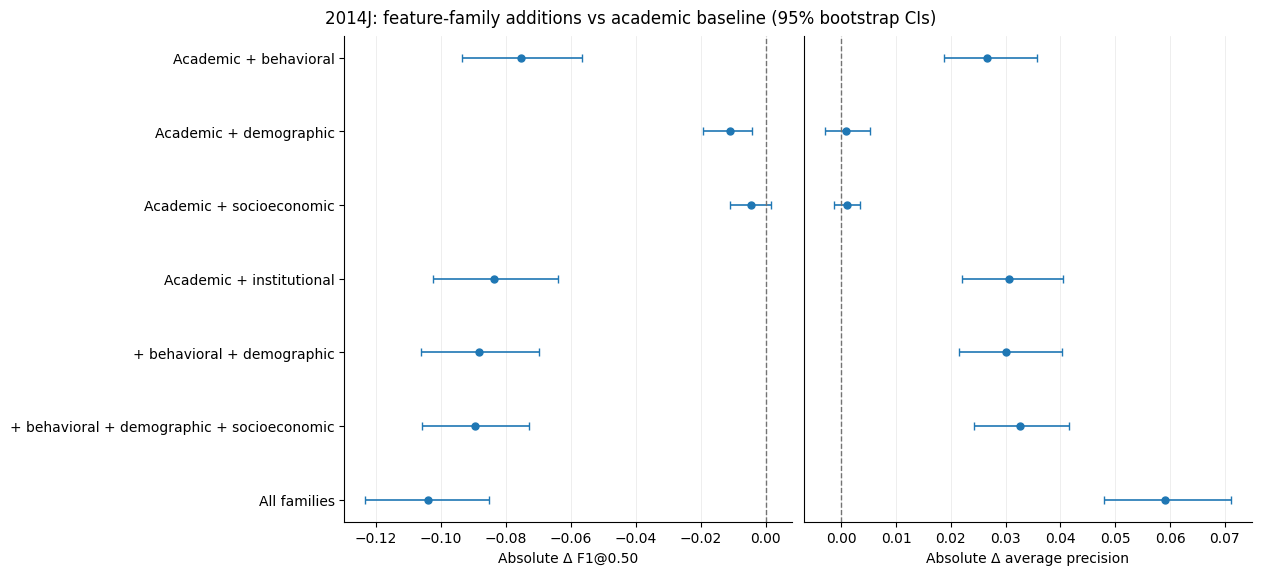

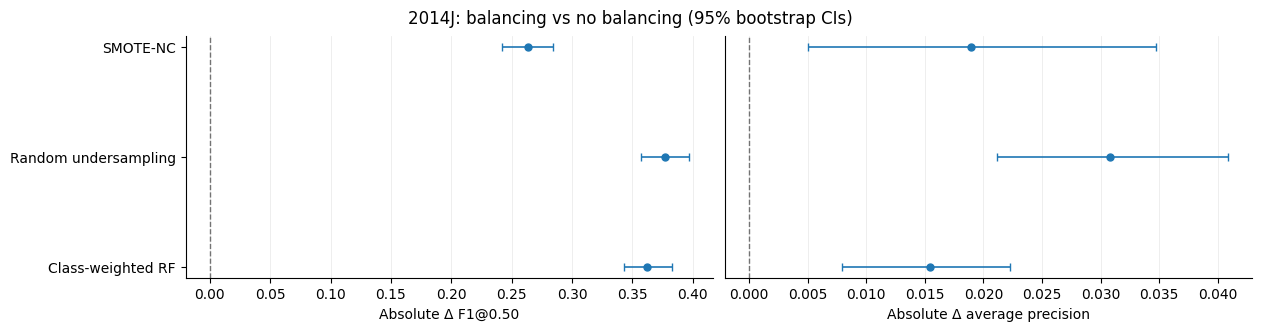

Candidate supplementary table — feature ablation:
                arm  CV F1  CV AP  2014J F1  2014J AP  2014J ΔF1  2014J ΔAP
               ACAD 0.0964 0.3521    0.1263    0.2626     0.0000     0.0000
           ACAD+BEH 0.1002 0.3694    0.0508    0.2892    -0.0755     0.0266
          ACAD+DEMO 0.0863 0.3584    0.1151    0.2634    -0.0112     0.0008
         ACAD+SOCIO 0.1002 0.3527    0.1218    0.2637    -0.0045     0.0011
          ACAD+INST 0.1687 0.3786    0.0425    0.2931    -0.0838     0.0306
      ACAD+BEH+DEMO 0.0875 0.3721    0.0380    0.2927    -0.0883     0.0301
ACAD+BEH+DEMO+SOCIO 0.0848 0.3720    0.0369    0.2952    -0.0894     0.0327
                ALL 0.1226 0.3870    0.0222    0.3217    -0.1041     0.0591


In [10]:
# Matplotlib is used to keep figure generation transparent and reproducible.
DISPLAY_ARMS = {
    "ACAD+BEH": "Academic + behavioral",
    "ACAD+DEMO": "Academic + demographic",
    "ACAD+SOCIO": "Academic + socioeconomic",
    "ACAD+INST": "Academic + institutional",
    "ACAD+BEH+DEMO": "+ behavioral + demographic",
    "ACAD+BEH+DEMO+SOCIO": "+ behavioral + demographic + socioeconomic",
    "ALL": "All families",
    "SMOTENC": "SMOTE-NC",
    "UNDERSAMPLING": "Random undersampling",
    "COST_SENSITIVE": "Class-weighted RF",
}


def plot_paired_differences(ci_table, title, file_name):
    """Compact, paper-ready two-panel absolute-difference forest plot."""
    fig, axes = plt.subplots(1, 2, figsize=(12.5, max(3.2, 1.3 + 0.62 * len(ci_table))),
                             constrained_layout=True, sharey=True)
    positions = np.arange(len(ci_table))
    for ax, metric, xlabel in zip(axes, ["f1", "ap"], ["Absolute Δ F1@0.50", "Absolute Δ average precision"]):
        points = ci_table[f"delta_{metric}"].to_numpy()
        lower = ci_table[f"ci95_lo_{metric}"].to_numpy()
        upper = ci_table[f"ci95_hi_{metric}"].to_numpy()
        ax.errorbar(points, positions, xerr=np.vstack([points - lower, upper - points]),
                    fmt="o", capsize=3, elinewidth=1.2, markersize=5)
        ax.axvline(0, linewidth=1, linestyle="--", color="0.45")
        ax.set_yticks(positions, [DISPLAY_ARMS.get(a, a) for a in ci_table["arm"]])
        if ax is axes[1]:
            ax.tick_params(axis="y", which="both", labelleft=False, length=0)
        if ax is axes[1]:
            ax.tick_params(axis="y", which="both", labelleft=False, length=0)
        if ax is axes[0]:
            ax.invert_yaxis()
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", linewidth=0.5, alpha=0.30)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontsize=12)
    fig.savefig(RESULTS_DIR / file_name, dpi=200, bbox_inches="tight")
    plt.show()

plot_paired_differences(temporal_feature_cis,
                        "2014J: feature-family additions vs academic baseline (95% bootstrap CIs)",
                        "figure_S1_temporal_feature_families.png")
plot_paired_differences(temporal_balancing_cis,
                        "2014J: balancing vs no balancing (95% bootstrap CIs)",
                        "figure_S2_temporal_balancing.png")

# Compact combined table, recommended for manuscript/supplement.
feature_cv_table = feature_cv_summary.set_index("arm")[["f1", "ap"]].rename(
    columns={"f1": "CV F1", "ap": "CV AP"})
temporal_table = temporal_features.set_index("arm")[["f1", "ap", "delta_f1", "delta_ap"]].rename(
    columns={"f1": "2014J F1", "ap": "2014J AP", "delta_f1": "2014J ΔF1", "delta_ap": "2014J ΔAP"})
publication_table = feature_cv_table.join(temporal_table).reset_index()
publication_table.to_csv(RESULTS_DIR / "table_feature_CV_vs_2014J.csv", index=False)
print("Candidate supplementary table — feature ablation:")
print(publication_table.round(4).to_string(index=False))

### 7.1. Numerical reproducibility against the manuscript's original Table 6

The originally reported configurations are reproduced on the **supplied original folds**. Minor fourth-decimal differences may occur across libraries or environments; they must be documented rather than silently overwritten. The values below are transcribed from the manuscript/notebook rounded outputs for the seven original arms and are compared only to *like-for-like* CV results, not to `2014J` hold-out values.

In [11]:
# Reference metrics, at approximately four decimals, from the previously reported Table 6.
TABLE_6_REFERENCES = {
    ("features", "ACAD"): (0.0964, 0.3521),
    ("features", "ACAD+BEH"): (0.1002, 0.3694),
    ("features", "ALL"): (0.1230, 0.3869),
    ("balancing", "NONE"): (0.1230, 0.3869),
    ("balancing", "SMOTENC"): (0.3540, 0.3546),
    ("balancing", "UNDERSAMPLING"): (0.4139, 0.3766),
    ("balancing", "COST_SENSITIVE"): (0.4219, 0.3846),
}
comparison_rows = []
for (block, arm), (paper_f1, paper_ap) in TABLE_6_REFERENCES.items():
    selected_rows = feature_cv if block == "features" else balance_cv
    selected_rows = selected_rows[selected_rows.arm.eq(arm)]
    rerun_f1, rerun_ap = selected_rows.f1.mean(), selected_rows.ap.mean()
    comparison_rows.append({"block": block, "arm": arm,
                            "published_F1_rounded": paper_f1, "replicated_F1": rerun_f1,
                            "absolute_difference_F1": rerun_f1 - paper_f1,
                            "published_AP_rounded": paper_ap, "replicated_AP": rerun_ap,
                            "absolute_difference_AP": rerun_ap - paper_ap})
replication_comparison = pd.DataFrame(comparison_rows)
replication_comparison.to_csv(RESULTS_DIR / "comparison_to_original_table6.csv", index=False)
print(replication_comparison.round(5).to_string(index=False))
assert replication_comparison[["absolute_difference_F1", "absolute_difference_AP"]].abs().max().max() < 0.002

# Machine-readable provenance manifest, deliberately excluding any user identifiers.
manifest = {
    "study": "OULAD day-30 controlled ablation",
    "feature_input": FEATURE_FILE.name,
    "fold_input": FOLD_FILE.name,
    "sha256_features": sha256_file(FEATURE_FILE),
    "sha256_folds": sha256_file(FOLD_FILE),
    "n_rows": len(features), "n_features": features.shape[1],
    "n_withdrawn": int(labels.sum()), "prevalence": float(labels.mean()),
    "feature_families": {k: len(v) for k, v in FEATURE_FAMILIES.items()},
    "cv": "original student-grouped 5 folds × 3 repeats",
    "temporal_train": int(len(train_positions)), "temporal_2014J_test": int(len(test_positions)),
    "temporal_student_overlap_purged": purged_rows,
    "late_registration_records_requiring_audit": late_registration_count,
    "decision_threshold": DECISION_THRESHOLD,
    "bootstrap_repetitions": N_BOOTSTRAP,
    "rng_seed": RANDOM_STATE,
    "average_precision_definition": "sklearn.metrics.average_precision_score",
    "sklearn_version": sklearn.__version__,
    "imblearn_version": imblearn.__version__,
    "inference": "Nadeau-Bengio corrected paired t; Holm within endpoint/block; student-clustered paired percentile bootstrap for 2014J",
}
(RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Created", len(list(RESULTS_DIR.iterdir())), "files in", RESULTS_DIR)

    block            arm  published_F1_rounded  replicated_F1  absolute_difference_F1  published_AP_rounded  replicated_AP  absolute_difference_AP
 features           ACAD                0.0964        0.09641                 0.00001                0.3521        0.35214                 0.00004
 features       ACAD+BEH                0.1002        0.10015                -0.00005                0.3694        0.36941                 0.00001
 features            ALL                0.1230        0.12264                -0.00036                0.3869        0.38696                 0.00006
balancing           NONE                0.1230        0.12264                -0.00036                0.3869        0.38696                 0.00006
balancing        SMOTENC                0.3540        0.35430                 0.00030                0.3546        0.35478                 0.00018
balancing  UNDERSAMPLING                0.4139        0.41394                 0.00004                0.3766        0.3

## 8. Results synthesis for the revised ablation section

**Research question and design.** The controlled experiment compares the same Random Forest classifier, day-30 target, folds and evaluation protocol while varying the feature-family composition or the class-imbalance strategy. It complements the scoping review, where descriptive differences between papers cannot identify the effects of predictors or resampling because institutions, outcomes and protocols differ.

**Feature enrichment.** Using the original grouped CV folds, adding behavioral-engagement proxies to academic information increases **AP by +0.0173** but F1@0.50 by only **+0.0037**; the latter is not significant after the expanded Holm adjustment. Adding all five families increases **AP by +0.0348** and F1@0.50 by **+0.0262**. The AP increase remains statistically supported under the expanded tests, whereas the F1 change does not (expanded Holm p ≈ 0.0785). Among one-family additions, the institutional block yields the largest F1 in this particular CV experiment, demonstrating non-monotonic feature contributions.

**Temporal stress test.** With all 2014J observations held out and student identities excluded from the earlier-presentation training set, the all-feature configuration produces **higher AP than ACAD (+0.0591, 95% clustered-bootstrap CI [+0.0479, +0.0712])** but **lower fixed-threshold F1 (−0.1041, CI [−0.1236, −0.0854])**. This discordance must not be smoothed away: it exposes an operational weakness of the uncalibrated 0.50 threshold in 2014J, despite better discrimination/ranking by AP.

**Balance handling.** In grouped CV, training-time resampling and class weighting substantially improve F1 but fail to improve AP relative to natural prevalence. In 2014J, undersampling has higher F1, recall and AP than the unbalanced model, although at a material cost in precision. The direction of the changes therefore depends on both metric and evaluation period.

**Scope of inference.** These results are *within-dataset* sensitivity and robustness checks, **not** evidence that particular variable families or balancing methods are uniformly superior. No hyperparameters or decision thresholds were tuned on the hold-out. The sample contains potentially late registrations, and the temporal availability of some engineered inputs requires a separate audit of the feature-generation pipeline. Consequently, the correct contribution to the paper is improved transparency about methodological sensitivity, not a claim of universal causal or transportable improvements.